# PART 3: EDA, Visualization & Benchmarking


In [1]:
%pip install --default-timeout=120 --retries 10 scipy


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install --default-timeout=120 --retries 10 pyarrow


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install --force-reinstall "pandas==2.2.3" "pyarrow==23.0.1"

  Using cached pandas-2.2.3-cp312-cp312-macosx_11_0_arm64.whl.metadata (89 kB)
  Using cached pyarrow-23.0.1-cp312-cp312-macosx_12_0_arm64.whl.metadata (3.1 kB)
  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached python_dateutil-3.0.0-py2.py3-none-any.whl.metadata (8.2 kB)
  Using cached pytz-2026.6-py2.py3-none-any.whl.metadata (22 kB)
  Using cached tzdata-2026.6-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
Using cached pandas-2.2.3-cp312-cp312-macosx_11_0_arm64.whl (11.4 MB)
Using cached pyarrow-23.0.1-cp312-cp312-macosx_12_0_arm64.whl (34.2 MB)
Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl (5.5 MB)
Using cached python_dateutil-3.0.0-py2.py3-none-any.whl (94 kB)
Using cached pytz-2026.6-py2.py3-none-any.whl (506 kB)
Using cached tzdata-2026.6-py2.py3-none-any.whl (348 kB)
Using cached six-1.17.0-py2.py3-none-any.whl (11 kB)
  Attempting uninstall: pytz
    Found existing

In [4]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("final_merged_data.csv")
df["Month"] = df["YearMonth"].str[-2:].astype(int)

# Geographic groups used throughout the analysis
SOUTH = ["ES70", "ES51", "ES30", "EL30"]          # Canarias, Barcelona, Madrid, Athens
df["Group"] = np.where(df["NUTS_CODE"].isin(SOUTH), "Hot South", "North / Capitals")
df["Label"] = df["City"] + " (" + df["NUTS_CODE"] + ")"

# Region order: by mean comfort, so every plot reads from "cool" to "warm"
order = df.groupby("City")["Comfort_Days_pct"].mean().sort_values().index.tolist()

print(df.shape)
print(df.groupby("Group")["City"].unique())
df.head()

(360, 22)
Group
Hot South                       [Athens, Madrid, Barcelona, Canarias]
North / Capitals    [Vienna, Prague, Berlin, Paris, Amsterdam, Sto...
Name: City, dtype: object


,NUTS_CODE,City_Center,YearMonth,Nights_Count,Status,Year,Annual_Nights,Nights_Share_pct,City,T_max_mean,...,Comfort_Days_pct,Valid_Days,Days_Recorded,Days_in_Month,Weather_Coverage_pct,Wiki_Rank,Source_URL,Month,Group,Label
0,AT13,Vienna,2022-01,292156,NaN,2022,12624154,2.314262,Vienna,5.435484,...,0.000000,31,31,31,100.0,NaN,NaN,1,North / Capitals,Vienna (AT13)
1,AT13,Vienna,2022-02,385182,NaN,2022,12624154,3.051151,Vienna,9.192857,...,0.000000,28,28,28,100.0,NaN,NaN,2,North / Capitals,Vienna (AT13)
2,AT13,Vienna,2022-03,666060,NaN,2022,12624154,5.276076,Vienna,11.154839,...,19.354839,31,31,31,100.0,NaN,NaN,3,North / Capitals,Vienna (AT13)
3,AT13,Vienna,2022-04,1005913,NaN,2022,12624154,7.968162,Vienna,13.830000,...,23.333333,30,30,30,100.0,NaN,NaN,4,North / Capitals,Vienna (AT13)
4,AT13,Vienna,2022-05,1167222,NaN,2022,12624154,9.245942,Vienna,22.403226,...,93.548387,31,31,31,100.0,NaN,NaN,5,North / Capitals,Vienna (AT13)


## 1. Descriptive statistics


In [5]:
cols = ["Nights_Share_pct", "Comfort_Days_pct", "T_max_mean", "Rain_Total_mm", "Sunshine_Total_hours"]
print(df[cols].describe().round(2))

print("\nPer-region summary:")
summary = df.groupby("City").agg(
    Share_mean=("Nights_Share_pct", "mean"),
    Share_std=("Nights_Share_pct", "std"),
    Comfort_mean=("Comfort_Days_pct", "mean"),
    Tmax_mean=("T_max_mean", "mean"),
).round(2).loc[order]
summary

       Nights_Share_pct  Comfort_Days_pct  T_max_mean  Rain_Total_mm  \
count            360.00            360.00      360.00         360.00   
mean               8.33             37.60       17.99          56.94   
std                2.50             33.93        8.02          38.04   
min                2.08              0.00       -1.50           0.40   
25%                7.06              0.00       11.79          29.18   
50%                8.58             35.48       18.70          50.80   
75%                9.53             67.74       24.48          77.05   
max               19.92            100.00       36.81         241.60   

       Sunshine_Total_hours  
count                360.00  
mean                 270.86  
std                  102.94  
min                   28.71  
25%                  201.25  
50%                  287.36  
75%                  358.67  
max                  454.77  

Per-region summary:


,Share_mean,Share_std,Comfort_mean,Tmax_mean
City,,,,
Stockholm,8.33,2.08,24.55,11.14
Amsterdam,8.33,2.49,28.77,14.77
Prague,8.33,2.03,29.24,15.75
Vienna,8.33,2.21,29.77,16.51
Madrid,8.33,0.99,30.69,21.95
Berlin,8.33,1.80,31.32,15.27
Paris,8.33,1.29,32.93,16.83
Athens,8.33,3.34,35.93,22.90
Barcelona,8.33,5.17,47.14,21.38


## 2. Correlation analysis


In [6]:
climate_vars = ["Comfort_Days_pct", "T_max_mean", "Sunshine_Total_hours", "Rain_Total_mm"]
target = "Nights_Share_pct"

def corr_pair(x, y):
    r, p = stats.pearsonr(x, y)
    rho, ps = stats.spearmanr(x, y)
    return pd.Series({"Pearson_r": r, "Pearson_p": p, "Spearman_rho": rho, "Spearman_p": ps})

# (a) pooled
pooled = pd.DataFrame({v: corr_pair(df[v], df[target]) for v in climate_vars}).T
print("(a) POOLED (n=360)"); print(pooled.round(3))

# (c) region-demeaned: removes between-region differences
dm = df.copy()
for v in climate_vars + [target]:
    dm[v] = dm[v] - dm.groupby("NUTS_CODE")[v].transform("mean")
within = pd.DataFrame({v: corr_pair(dm[v], dm[target]) for v in climate_vars}).T
print("\n(c) REGION-DEMEANED (seasonal co-movement only)"); print(within.round(3))

(a) POOLED (n=360)
                      Pearson_r  Pearson_p  Spearman_rho  Spearman_p
Comfort_Days_pct          0.345       0.00         0.428       0.000
T_max_mean                0.590       0.00         0.639       0.000
Sunshine_Total_hours      0.534       0.00         0.612       0.000
Rain_Total_mm             0.037       0.48         0.066       0.209

(c) REGION-DEMEANED (seasonal co-movement only)
                      Pearson_r  Pearson_p  Spearman_rho  Spearman_p
Comfort_Days_pct          0.398       0.00         0.510       0.000
T_max_mean                0.676       0.00         0.755       0.000
Sunshine_Total_hours      0.573       0.00         0.665       0.000
Rain_Total_mm             0.041       0.44         0.058       0.269


In [7]:
# (b) per region: Comfort vs share and Temperature vs share
rows = []
for city, g in df.groupby("City"):
    r1, p1 = stats.pearsonr(g["Comfort_Days_pct"], g[target]) if g["Comfort_Days_pct"].std() > 0 else (np.nan, np.nan)
    s1, _ = stats.spearmanr(g["Comfort_Days_pct"], g[target])
    r2, p2 = stats.pearsonr(g["T_max_mean"], g[target])
    s2, _ = stats.spearmanr(g["T_max_mean"], g[target])
    rows.append({"City": city, "Group": g["Group"].iloc[0],
                 "Comfort_Pearson": r1, "Comfort_Spearman": s1, "Comfort_p": p1,
                 "Temp_Pearson": r2, "Temp_Spearman": s2, "Temp_p": p2,
                 "Comfort_std": g["Comfort_Days_pct"].std()})
per_region = pd.DataFrame(rows).set_index("City").loc[order]
print("(b) PER REGION (n=36 each)")
per_region.round(3)

(b) PER REGION (n=36 each)


,Group,Comfort_Pearson,Comfort_Spearman,Comfort_p,Temp_Pearson,Temp_Spearman,Temp_p,Comfort_std
City,,,,,,,,
Stockholm,North / Capitals,0.832,0.872,0.000,0.894,0.930,0.000,32.714
Amsterdam,North / Capitals,0.797,0.849,0.000,0.868,0.884,0.000,31.999
Prague,North / Capitals,0.548,0.500,0.001,0.627,0.580,0.000,29.129
Vienna,North / Capitals,0.440,0.395,0.007,0.518,0.467,0.001,28.431
Madrid,Hot South,0.546,0.513,0.001,0.572,0.584,0.000,29.306
Berlin,North / Capitals,0.707,0.842,0.000,0.786,0.870,0.000,32.597
Paris,North / Capitals,0.693,0.782,0.000,0.723,0.776,0.000,30.324
Athens,Hot South,0.022,0.041,0.900,0.957,0.943,0.000,34.455
Barcelona,Hot South,0.223,0.436,0.192,0.940,0.952,0.000,29.881


In [8]:
# Per geographic group (pooled within group, region-demeaned to avoid between-city effects)
for grp, g in dm.assign(Group=df["Group"]).groupby("Group"):
    r, p = stats.pearsonr(g["Comfort_Days_pct"], g[target])
    rho, ps = stats.spearmanr(g["Comfort_Days_pct"], g[target])
    print(f"{grp:17s} n={len(g):3d} | Comfort vs Share (demeaned): Pearson r={r:+.3f} (p={p:.3g}), Spearman rho={rho:+.3f} (p={ps:.3g})")

Hot South         n=144 | Comfort vs Share (demeaned): Pearson r=+0.145 (p=0.0839), Spearman rho=+0.258 (p=0.0018)
North / Capitals  n=216 | Comfort vs Share (demeaned): Pearson r=+0.665 (p=6.48e-29), Spearman rho=+0.687 (p=1.68e-31)


## 3. Hot South vs North / Capitals

In [9]:
g_cmp = df.groupby("Group").agg(
    Comfort_mean=("Comfort_Days_pct", "mean"),
    Tmax_mean=("T_max_mean", "mean"),
    Rain_mean_mm=("Rain_Total_mm", "mean"),
    Sunshine_mean_h=("Sunshine_Total_hours", "mean"),
    Share_std=("Nights_Share_pct", "std"),
).round(2)
print(g_cmp)

# Seasonality strength = peak share / trough share, per region
amp = (df.groupby(["City", "Month"])["Nights_Share_pct"].mean().groupby("City")
         .agg(lambda s: s.max() / s.min()).rename("Peak_to_trough"))
amp = amp.to_frame().join(df.drop_duplicates("City").set_index("City")["Group"]).sort_values("Peak_to_trough", ascending=False)
print("\nSeasonality strength (max month share / min month share):")
print(amp.round(2))

# Welch t-test: is the seasonal swing different between groups?
a = df[df.Group == "Hot South"]["Nights_Share_pct"]; b = df[df.Group == "North / Capitals"]["Nights_Share_pct"]
print("\nLevene test of equal variance (share): p = %.4f" % stats.levene(a, b).pvalue)

                  Comfort_mean  Tmax_mean  Rain_mean_mm  Sunshine_mean_h  \
Group                                                                      
Hot South                49.86      22.41         42.72           314.91   
North / Capitals         29.43      15.05         66.42           241.49   

                  Share_std  
Group                        
Hot South              3.11  
North / Capitals       1.99  

Seasonality strength (max month share / min month share):
           Peak_to_trough             Group
City                                       
Barcelona            6.78         Hot South
Athens               3.46         Hot South
Amsterdam            2.70  North / Capitals
Vienna               2.51  North / Capitals
Prague               2.37  North / Capitals
Stockholm            2.35  North / Capitals
Berlin               2.15  North / Capitals
Paris                1.58  North / Capitals
Madrid               1.52         Hot South
Canarias             1.34       

## 4. Six key visualizations

### Plot 1. Climate profile: mean monthly max temperature by region

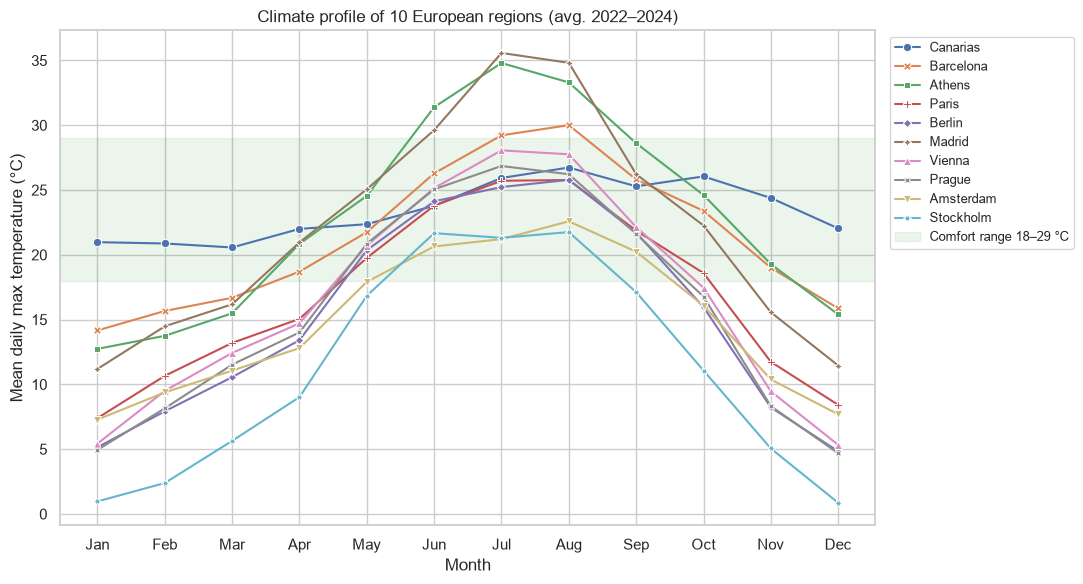

In [10]:
clim = df.groupby(["City", "Month"])["T_max_mean"].mean().reset_index()
fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(data=clim, x="Month", y="T_max_mean", hue="City", hue_order=order[::-1],
             style="City", style_order=order[::-1], markers=True, dashes=False, ax=ax)
ax.axhspan(18, 29, color="green", alpha=0.08, label="Comfort range 18–29 °C")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_xlabel("Month"); ax.set_ylabel("Mean daily max temperature (°C)")
ax.set_title("Climate profile of 10 European regions (avg. 2022–2024)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
plt.tight_layout(); plt.savefig("figures/01_climate_profile.png", dpi=150); plt.show()

### Plot 2. Tourism seasonality: share of annual nights by month

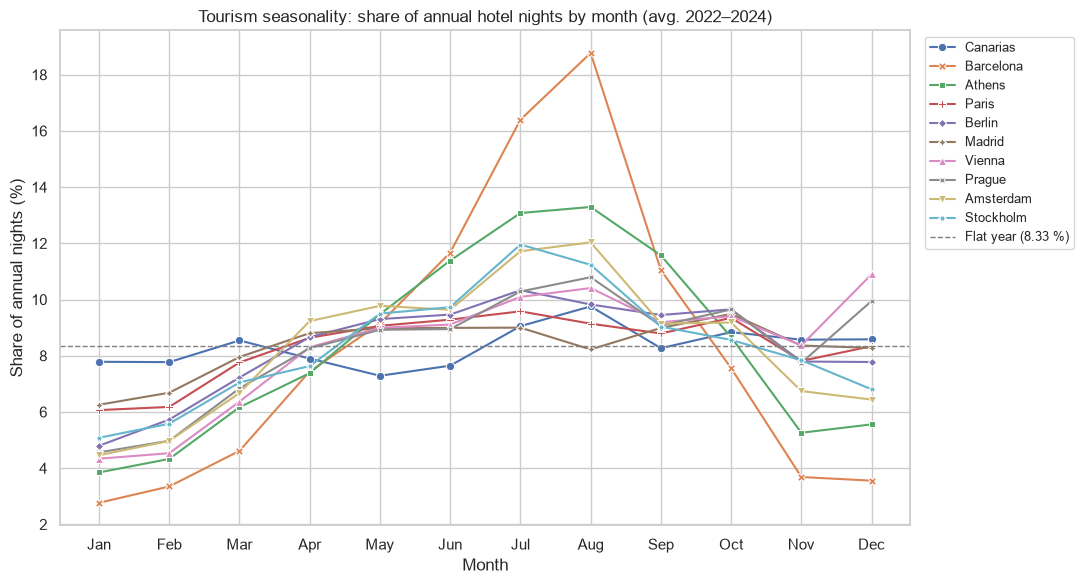

In [11]:
seas = df.groupby(["City", "Month"])["Nights_Share_pct"].mean().reset_index()
fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(data=seas, x="Month", y="Nights_Share_pct", hue="City", hue_order=order[::-1],
             style="City", style_order=order[::-1], markers=True, dashes=False, ax=ax)
ax.axhline(100/12, color="grey", ls="--", lw=1, label="Flat year (8.33 %)")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_xlabel("Month"); ax.set_ylabel("Share of annual nights (%)")
ax.set_title("Tourism seasonality: share of annual hotel nights by month (avg. 2022–2024)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
plt.tight_layout(); plt.savefig("figures/02_tourism_seasonality.png", dpi=150); plt.show()

### Plot 3. Comfort vs nights on one 0–100 scale
Both series are put on a 0–100 scale: comfort is already a percentage; the nights share is min-max rescaled **within each region** (0 = quietest month, 100 = busiest month), so shapes of the seasonal curves can be compared directly.

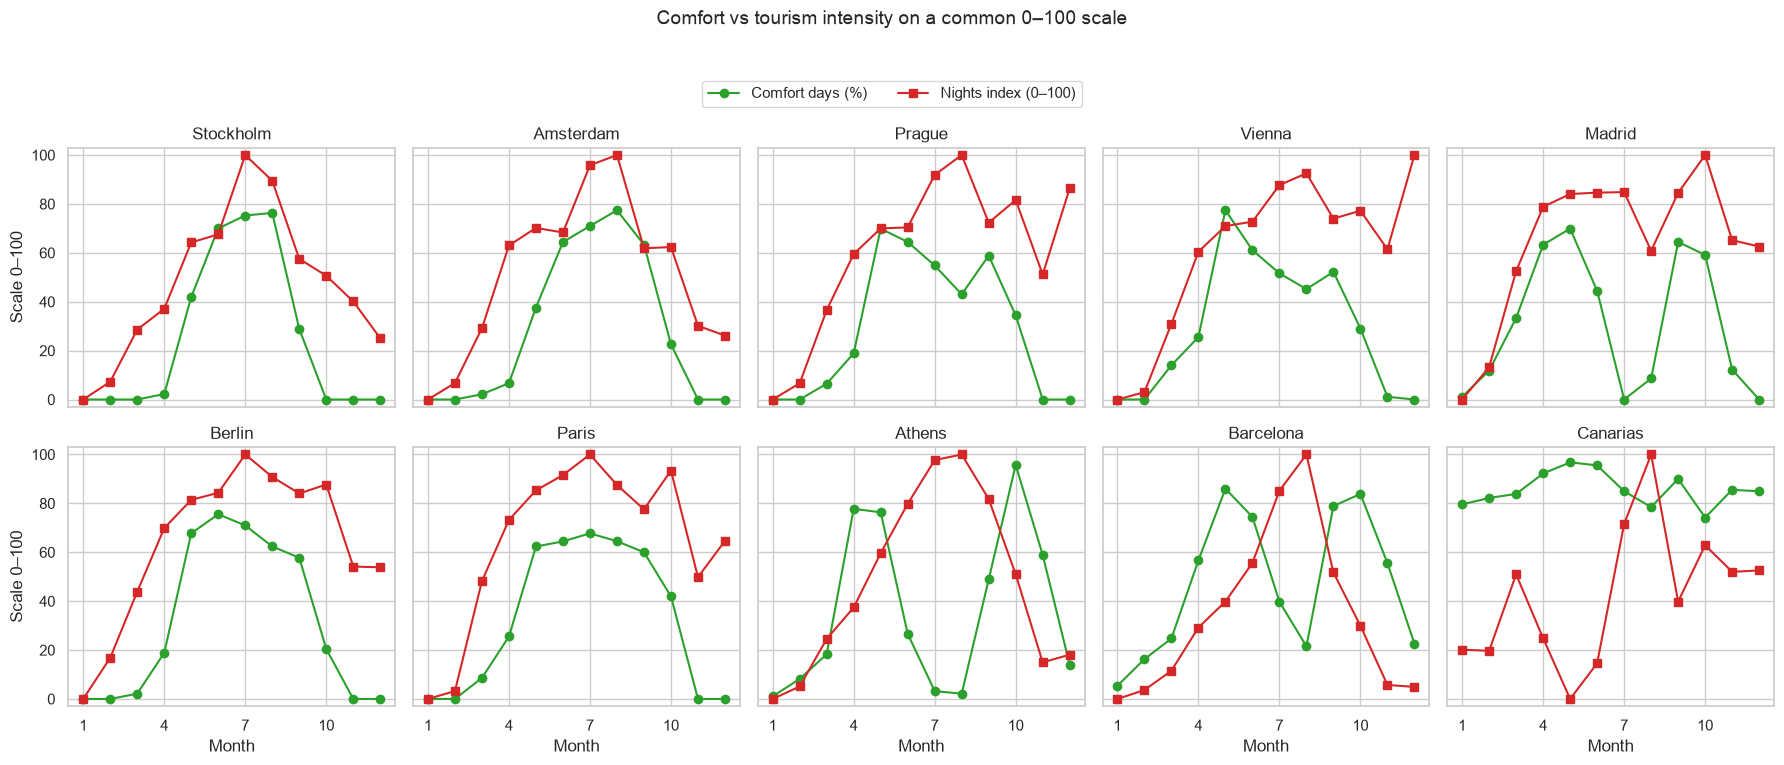

In [12]:
m = df.groupby(["City", "Month"])[["Comfort_Days_pct", "Nights_Share_pct"]].mean().reset_index()
m["Nights_Index_0_100"] = m.groupby("City")["Nights_Share_pct"].transform(lambda s: (s - s.min()) / (s.max() - s.min()) * 100)

fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharex=True, sharey=True)
for ax, city in zip(axes.ravel(), order):
    d = m[m.City == city]
    ax.plot(d["Month"], d["Comfort_Days_pct"], marker="o", color="tab:green", label="Comfort days (%)")
    ax.plot(d["Month"], d["Nights_Index_0_100"], marker="s", color="tab:red", label="Nights index (0–100)")
    ax.set_title(city); ax.set_ylim(-3, 103); ax.set_xticks([1, 4, 7, 10])
for ax in axes[:, 0]: ax.set_ylabel("Scale 0–100")
for ax in axes[1, :]: ax.set_xlabel("Month")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=11)
fig.suptitle("Comfort vs tourism intensity on a common 0–100 scale", y=1.09, fontsize=14)
plt.tight_layout(); plt.savefig("figures/03_comfort_vs_nights.png", dpi=150, bbox_inches="tight"); plt.show()

### Plot 4. Heatmap: region × month (tourism intensity)

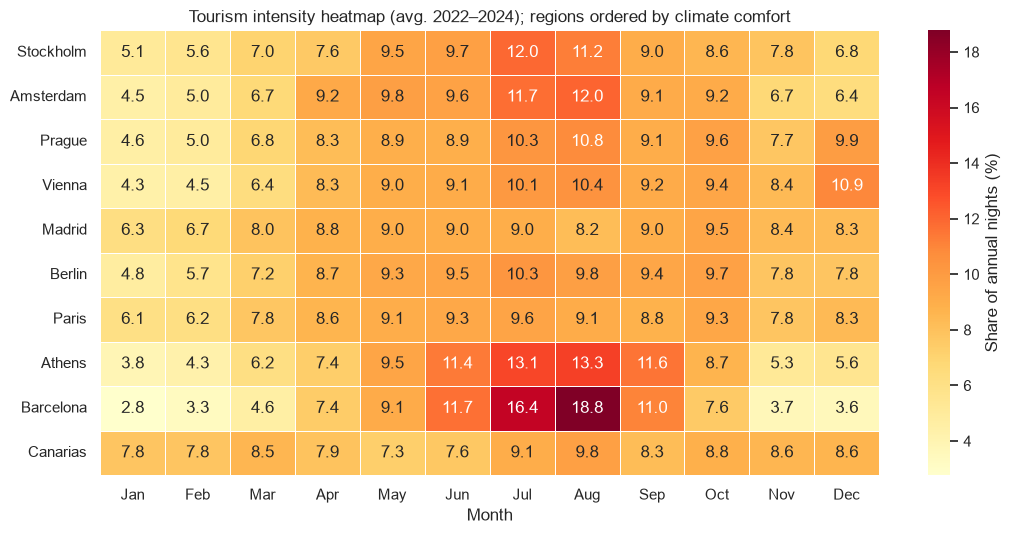

In [13]:
heat = df.pivot_table(index="City", columns="Month", values="Nights_Share_pct", aggfunc="mean").loc[order]
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Share of annual nights (%)"},
            linewidths=0.4, ax=ax)
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], rotation=0)
ax.set_xlabel("Month"); ax.set_ylabel("")
ax.set_title("Tourism intensity heatmap (avg. 2022–2024); regions ordered by climate comfort")
plt.tight_layout(); plt.savefig("figures/04_heatmap.png", dpi=150); plt.show()

### Plot 5. Peak comparison: month of max comfort vs month of peak nights
For regions with a flat comfort curve (Canarias) the max-comfort month is not well defined, since many months tie; we plot the **first** maximum and discuss this in the findings.

           Peak_Comfort_Month  Peak_Nights_Month  Gap_months  \
City                                                           
Stockholm                   8                  7          -1   
Amsterdam                   8                  8           0   
Prague                      5                  8           3   
Vienna                      5                 12          -5   
Madrid                      5                 10           5   
Berlin                      6                  7           1   
Paris                       7                  7           0   
Athens                     10                  8          -2   
Barcelona                   5                  8           3   
Canarias                    5                  8           3   

           Comfort_at_peak_pct  Comfort_in_nights_peak_pct  
City                                                        
Stockholm                 76.3                        75.3  
Amsterdam                 77.4                  

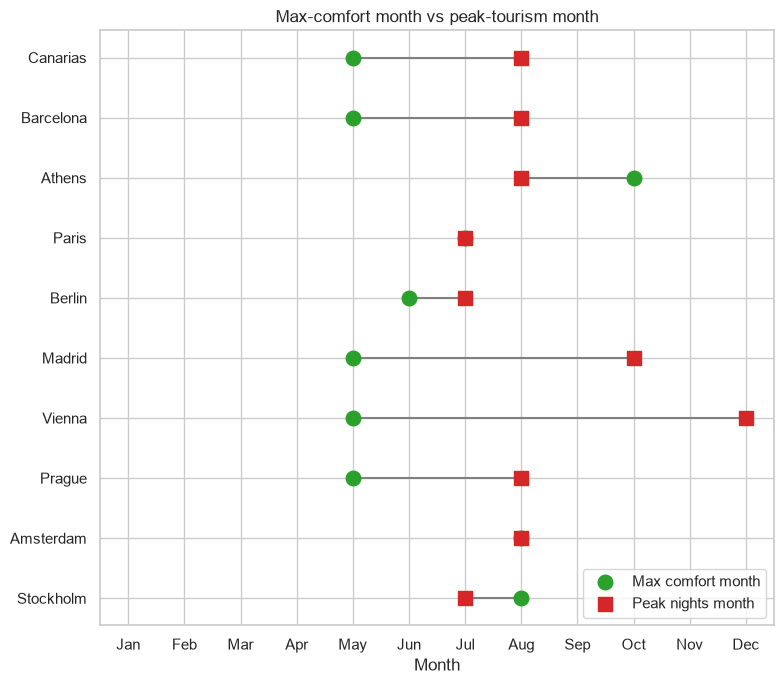

In [14]:
peaks = []
for city, g in m.groupby("City"):
    mc = g.loc[g["Comfort_Days_pct"].idxmax(), "Month"]
    mn = g.loc[g["Nights_Share_pct"].idxmax(), "Month"]
    diff = (mn - mc + 6) % 12 - 6          # circular difference in months (Dec and Jan are neighbours)
    peaks.append({"City": city, "Peak_Comfort_Month": int(mc), "Peak_Nights_Month": int(mn),
                  "Gap_months": int(diff), "Comfort_at_peak_pct": g["Comfort_Days_pct"].max(),
                  "Comfort_in_nights_peak_pct": g.loc[g["Nights_Share_pct"].idxmax(), "Comfort_Days_pct"]})
peaks = pd.DataFrame(peaks).set_index("City").loc[order]
print(peaks.round(1))

fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(peaks))
ax.hlines(y, peaks["Peak_Comfort_Month"], peaks["Peak_Nights_Month"], color="grey", lw=1.5)
ax.scatter(peaks["Peak_Comfort_Month"], y, s=110, color="tab:green", label="Max comfort month", zorder=3)
ax.scatter(peaks["Peak_Nights_Month"], y, s=110, color="tab:red", marker="s", label="Peak nights month", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(peaks.index); ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_xlim(0.5, 12.5); ax.set_xlabel("Month")
ax.set_title("Max-comfort month vs peak-tourism month")
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig("figures/05_peak_comparison.png", dpi=150); plt.show()

### Plot 6. Scatter: comfort vs share of nights, regression lines by geographic group

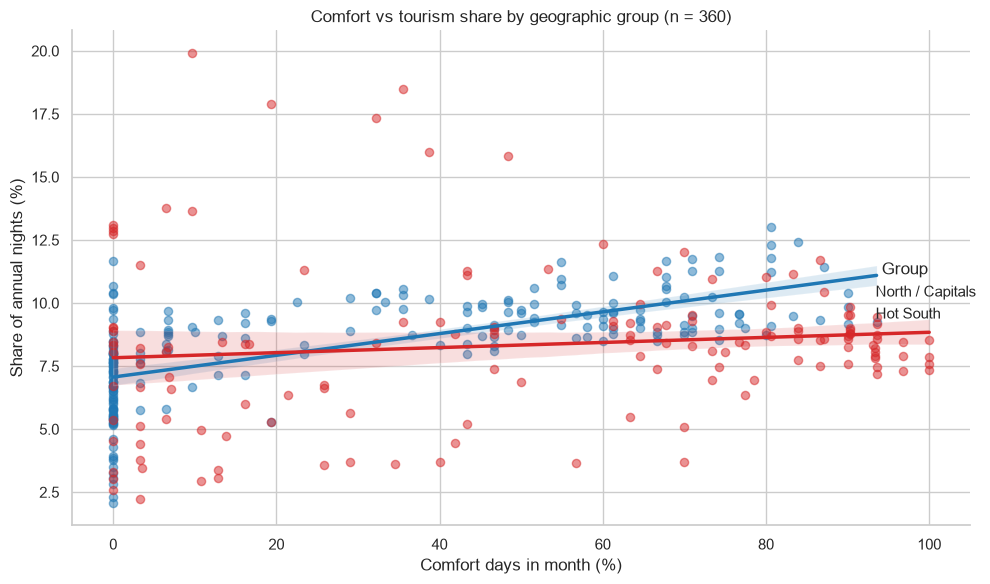

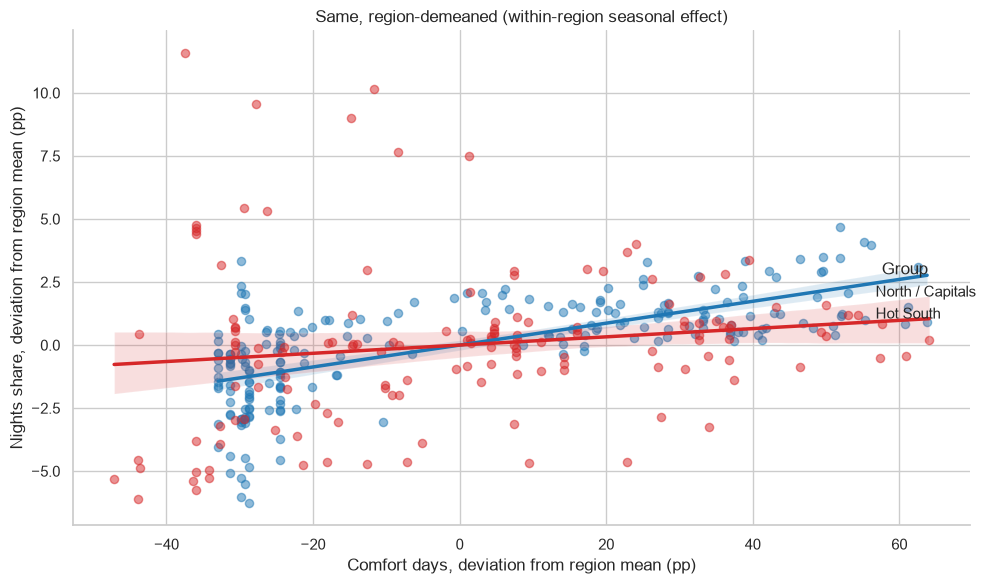

In [15]:
g = sns.lmplot(data=df, x="Comfort_Days_pct", y="Nights_Share_pct", hue="Group",
               palette={"Hot South": "tab:red", "North / Capitals": "tab:blue"},
               height=6, aspect=1.4, scatter_kws={"alpha": 0.5, "s": 35}, line_kws={"lw": 2.5})
g.set_axis_labels("Comfort days in month (%)", "Share of annual nights (%)")
g.ax.set_title("Comfort vs tourism share by geographic group (n = 360)")
plt.tight_layout(); plt.savefig("figures/06_scatter_regression.png", dpi=150); plt.show()

# Companion: same scatter after removing region means (seasonal effect only)
dm2 = dm.assign(Group=df["Group"])
g2 = sns.lmplot(data=dm2, x="Comfort_Days_pct", y="Nights_Share_pct", hue="Group",
                palette={"Hot South": "tab:red", "North / Capitals": "tab:blue"},
                height=6, aspect=1.4, scatter_kws={"alpha": 0.5, "s": 35}, line_kws={"lw": 2.5})
g2.set_axis_labels("Comfort days, deviation from region mean (pp)", "Nights share, deviation from region mean (pp)")
g2.ax.set_title("Same, region-demeaned (within-region seasonal effect)")
plt.tight_layout(); plt.savefig("figures/06b_scatter_demeaned.png", dpi=150); plt.show()

## 5. Robustness: is 2022 different?
2022 was still a post-COVID recovery year (winter 2022 had restrictions/low demand), which can distort within-year shares.

In [16]:
rob = []
for yr, g in dm.groupby("Year"):
    r, p = stats.pearsonr(g["Comfort_Days_pct"], g[target]); rho, _ = stats.spearmanr(g["Comfort_Days_pct"], g[target])
    rob.append({"Year": yr, "Pearson_r": r, "Spearman_rho": rho, "n": len(g)})
print(pd.DataFrame(rob).round(3))

# Year-to-year stability of the seasonal profile: corr between yearly share curves per region
stab = {}
for city, g in df.groupby("City"):
    p = g.pivot(index="Month", columns="Year", values="Nights_Share_pct")
    stab[city] = p.corr().loc[2022, 2024]
print("\nCorrelation of 2022 vs 2024 seasonal share curve per region:")
print(pd.Series(stab).sort_values().round(3))

   Year  Pearson_r  Spearman_rho    n
0  2022      0.454         0.562  120
1  2023      0.376         0.489  120
2  2024      0.362         0.491  120

Correlation of 2022 vs 2024 seasonal share curve per region:
Canarias     0.526
Paris        0.895
Amsterdam    0.925
Stockholm    0.949
Madrid       0.949
Berlin       0.950
Prague       0.951
Vienna       0.965
Athens       0.968
Barcelona    0.990
dtype: float64


## 6. Benchmark: CSV vs Parquet


In [17]:
N_REPEAT = 7

def timeit(fn, n=N_REPEAT):
    ts = []
    for _ in range(n):
        t0 = time.time(); fn(); ts.append(time.time() - t0)
    return float(np.median(ts))

def benchmark(frame, tag):
    csv_p, pq_p = f"bench_{tag}.csv", f"bench_{tag}.parquet"
    res = {
        "CSV":     {"write_s": timeit(lambda: frame.to_csv(csv_p, index=False)),
                    "read_s":  timeit(lambda: pd.read_csv(csv_p)),
                    "size_kb": os.path.getsize(csv_p) / 1024},
        "Parquet": {"write_s": timeit(lambda: frame.to_parquet(pq_p, index=False)),
                    "read_s":  timeit(lambda: pd.read_parquet(pq_p)),
                    "size_kb": os.path.getsize(pq_p) / 1024},
    }
    out = pd.DataFrame(res).T
    out["size_ratio_vs_csv"] = out["size_kb"] / out.loc["CSV", "size_kb"]
    return out

try:
    import pyarrow  # noqa: F401
    bench_small = benchmark(df.drop(columns=["Month", "Group", "Label"]), "small")
    print(f"Original dataset ({len(df)} rows):"); print(bench_small.round(5))

    big = pd.concat([df.drop(columns=["Month", "Group", "Label"])] * 1000, ignore_index=True)
    bench_big = benchmark(big, "big")
    print(f"\nEnlarged dataset ({len(big):,} rows):"); print(bench_big.round(4))
except ImportError:
    print("pyarrow is not installed -> run: pip install pyarrow, then re-run this cell")

Original dataset (360 rows):
         write_s   read_s   size_kb  size_ratio_vs_csv
CSV      0.00516  0.00124  51.34961            1.00000
Parquet  0.00140  0.00152  26.54688            0.51698

Enlarged dataset (360,000 rows):
         write_s  read_s     size_kb  size_ratio_vs_csv
CSV       1.8965  0.3254  51118.3955             1.0000
Parquet   0.1023  0.0222    238.8301             0.0047


## 7. Findings and limitations

*(Numbers below come from the outputs above; re-check them after your own run.)*

In [18]:
# helper: print the key numbers for the report
print("Pooled Comfort vs Share      : Pearson %.2f, Spearman %.2f" % (pooled.loc["Comfort_Days_pct","Pearson_r"], pooled.loc["Comfort_Days_pct","Spearman_rho"]))
print("Demeaned Comfort vs Share    : Pearson %.2f, Spearman %.2f" % (within.loc["Comfort_Days_pct","Pearson_r"], within.loc["Comfort_Days_pct","Spearman_rho"]))
print("Demeaned Temperature vs Share: Pearson %.2f, Spearman %.2f" % (within.loc["T_max_mean","Pearson_r"], within.loc["T_max_mean","Spearman_rho"]))
print("\nRegions with positive, significant (p<0.05) comfort-share correlation:")
print(per_region[(per_region["Comfort_Pearson"] > 0) & (per_region["Comfort_p"] < 0.05)].index.tolist())

Pooled Comfort vs Share      : Pearson 0.34, Spearman 0.43
Demeaned Comfort vs Share    : Pearson 0.40, Spearman 0.51
Demeaned Temperature vs Share: Pearson 0.68, Spearman 0.76

Regions with positive, significant (p<0.05) comfort-share correlation:
['Stockholm', 'Amsterdam', 'Prague', 'Vienna', 'Madrid', 'Berlin', 'Paris']
